# SalesInsight PY

**Ananda Carvalho · Desenvolvimento guiado com IA**

Análise descritiva de vendas sintéticas. Execute de cima para baixo. Código comentado para estudo.

| Requisitos | Implementação | Conferência |
|---|---|---|
| RF01–03 | CSV, inspeção, limpeza | 200 entradas; 194 válidas |
| RF04–06 | Colunas, métricas, segmentos | Totais e limites |
| RF07 | Quatro figuras | PNG, 150 dpi |
| RF08 | Funções, lambdas, classe | Execução |
| RF09–10 | CSV, JSON, main | Releitura e teste do zero |

## Dados e limpeza — RF01 a RF03

Um DataFrame é uma tabela. Linhas são vendas; colunas são características. O gerador usa seed=42 e preserva datas inválidas. Inspecionamos antes de limpar. Datas inválidas viram NaT. Os motivos de conversão podem se sobrepor; os totais de linhas mantidas alteradas e inalteradas são exclusivos. Aulas 13–18 e enunciado.

In [1]:
# RF01–RF03: gerar, ler, inspecionar e limpar.
import pandas as pd  # Importa os recursos utilizados nesta etapa.
import numpy as np  # Importa os recursos utilizados nesta etapa.
import random  # Importa os recursos utilizados nesta etapa.
from datetime import datetime, timedelta  # Importa os recursos utilizados nesta etapa.
from pathlib import Path  # Importa os recursos utilizados nesta etapa.
import json  # Importa os recursos utilizados nesta etapa.
import matplotlib.pyplot as plt  # Importa os recursos utilizados nesta etapa.


def gerar_dataset_vendas(n_registros=200, seed=42):  # Define uma função reutilizável com os parâmetros indicados.
    """Gera o dataset sintético do enunciado, incluindo datas inválidas."""
    random.seed(seed)  # Fixa a semente para reproduzir os mesmos sorteios.
    np.random.seed(seed)  # Fixa a semente para reproduzir os mesmos sorteios.
    produtos = ['Notebook', 'Smartphone', 'Tablet', 'Monitor', 'Teclado', 'Mouse', 'Headset']  # Calcula e guarda produtos para as próximas operações.
    categorias = {'Notebook': 'Computadores', 'Smartphone': 'Celulares', 'Tablet': 'Celulares', 'Monitor': 'Computadores', 'Teclado': 'Perifericos', 'Mouse': 'Perifericos', 'Headset': 'Perifericos'}  # Calcula e guarda categorias para as próximas operações.
    precos = {'Notebook': 3500, 'Smartphone': 2200, 'Tablet': 1800, 'Monitor': 1200, 'Teclado': 250, 'Mouse': 120, 'Headset': 350}  # Calcula e guarda precos para as próximas operações.
    regioes = ['Sudeste', 'Sul', 'Nordeste', 'Centro-Oeste', 'Norte']  # Calcula e guarda regioes para as próximas operações.
    data_inicio = datetime(2025, 1, 1)  # Calcula e guarda data_inicio para as próximas operações.
    dados = []  # Calcula e guarda dados para as próximas operações.
    for i in range(n_registros):  # Percorre os elementos, executando o bloco uma vez para cada item.
        produto = random.choice(produtos)  # Sorteia um item entre as opções disponíveis.
        categoria = categorias[produto]  # Calcula e guarda categoria para as próximas operações.
        quantidade = random.randint(1, 10)  # Sorteia um inteiro dentro dos limites inclusivos.
        preco = round(precos[produto] * random.uniform(0.85, 1.15), 2)  # Calcula e guarda preco para as próximas operações.
        data = data_inicio + timedelta(days=random.randint(0, 364))  # Sorteia um inteiro dentro dos limites inclusivos.
        data_txt = data.strftime('%Y-%m-%d')  # Calcula e guarda data_txt para as próximas operações.
        cliente = f'Cliente_{random.randint(1, 50):03d}'  # Sorteia um inteiro dentro dos limites inclusivos.
        if random.random() < 0.03:  # Executa o bloco somente quando esta condição é verdadeira.
            data_txt = 'DATA INVALIDA'  # Calcula e guarda data_txt para as próximas operações.
        dados.append({'id_venda': i + 1, 'data_venda': data_txt, 'cliente': cliente,  # Acrescenta o novo elemento à lista.
                      'produto': produto, 'categoria': categoria,  # Completa os campos do registro ou as opções de classificação.
                      'regiao': random.choice(regioes), 'quantidade': quantidade,  # Sorteia um item entre as opções disponíveis.
                      'preco_unitario': preco})  # Completa os campos do registro ou as opções de classificação.
    return pd.DataFrame(dados)  # Devolve o resultado para quem chamou a função.


def inspecionar_dados(df):  # Define uma função reutilizável com os parâmetros indicados.
    """Mostra a estrutura do DataFrame e retorna os dados sem modificá-los."""
    print('Shape:', df.shape)  # Exibe o resultado para inspeção e aprendizagem.
    print('Colunas:', list(df.columns))  # Exibe o resultado para inspeção e aprendizagem.
    print('Tipos:\n', df.dtypes)  # Exibe o resultado para inspeção e aprendizagem.
    print('Nulos:\n', df.isnull().sum())  # Exibe o resultado para inspeção e aprendizagem.
    print('Primeiras linhas:\n', df.head().to_string(index=False))  # Exibe o resultado para inspeção e aprendizagem.
    return df  # Devolve o resultado para quem chamou a função.


def tratar_dados(df):  # Define uma função reutilizável com os parâmetros indicados.
    """Retorna cópia limpa e contagens auditáveis; motivos podem se sobrepor."""
    limpo = df.copy()  # Cria uma cópia para preservar a tabela original.
    alteradas = pd.Series(False, index=df.index)  # Inicia uma marcação falsa para cada linha da tabela.
    relatorio = {'registros_iniciais': len(df)}  # Calcula e guarda relatorio para as próximas operações.
    textos_alterados = pd.Series(False, index=df.index)  # Inicia uma marcação falsa para cada linha da tabela.
    for coluna in ['cliente', 'produto', 'categoria', 'regiao', 'data_venda']:  # Percorre os elementos, executando o bloco uma vez para cada item.
        if pd.api.types.is_string_dtype(limpo[coluna]) or limpo[coluna].dtype == object:  # Executa o bloco somente quando esta condição é verdadeira.
            antes = limpo[coluna].copy()  # Cria uma cópia para preservar a tabela original.
            limpo[coluna] = limpo[coluna].str.strip()  # Calcula e guarda limpo[coluna] para as próximas operações.
            textos_alterados |= antes.fillna('') != limpo[coluna].fillna('')  # Acumula as marcações sem contar a mesma linha duas vezes.
    relatorio['linhas_texto_padronizado'] = int(textos_alterados.sum())  # Soma valores ou conta condições verdadeiras.
    alteradas |= textos_alterados  # Acumula as marcações sem contar a mesma linha duas vezes.
    antes_data = limpo['data_venda'].copy()  # Cria uma cópia para preservar a tabela original.
    limpo['data_venda'] = pd.to_datetime(antes_data, errors='coerce')  # Converte os valores para datas que o Pandas consegue manipular.
    invalidas = limpo['data_venda'].isna()  # Identifica valores ausentes, inclusive datas inválidas convertidas em NaT.
    convertidas = ~invalidas & ~antes_data.map(lambda x: isinstance(x, (datetime, pd.Timestamp)))  # Aplica o mapeamento a cada valor da coluna.
    relatorio['datas_convertidas'] = int(convertidas.sum())  # Soma valores ou conta condições verdadeiras.
    relatorio['datas_invalidas_removidas'] = int(invalidas.sum())  # Soma valores ou conta condições verdadeiras.
    alteradas |= convertidas  # Acumula as marcações sem contar a mesma linha duas vezes.
    for coluna, tipo in [('quantidade', int), ('preco_unitario', float)]:  # Percorre os elementos, executando o bloco uma vez para cada item.
        # Validar apenas registros que permanecerão depois da remoção das datas.
        valores = pd.to_numeric(limpo.loc[~invalidas, coluna], errors='raise')  # Seleciona as linhas indicadas pela condição ou pelo índice.
        if valores.isna().any() or not np.isfinite(valores).all():  # Executa o bloco somente quando esta condição é verdadeira.
            raise ValueError(f'{coluna}: valor ausente ou não finito; revisar a fonte.')  # Interrompe a execução com uma mensagem para corrigir a entrada.
        if coluna == 'quantidade' and ((valores % 1 != 0).any() or (valores <= 0).any()):  # Executa o bloco somente quando esta condição é verdadeira.
            raise ValueError('Quantidade deve ser inteira e positiva.')  # Interrompe a execução com uma mensagem para corrigir a entrada.
        if coluna == 'preco_unitario' and (valores < 0).any():  # Executa o bloco somente quando esta condição é verdadeira.
            raise ValueError('Preço não pode ser negativo.')  # Interrompe a execução com uma mensagem para corrigir a entrada.
        mudaram = ~limpo.loc[~invalidas, coluna].map(lambda x: isinstance(x, (int, np.integer) if tipo is int else (float, np.floating)))  # Aplica o mapeamento a cada valor da coluna.
        relatorio[coluna + '_convertidos'] = int(mudaram.sum())  # Soma valores ou conta condições verdadeiras.
        alteradas.loc[mudaram.index] |= mudaram  # Seleciona as linhas indicadas pela condição ou pelo índice.
    limpo = limpo.loc[~invalidas].copy()  # Cria uma cópia para preservar a tabela original.
    limpo['quantidade'] = limpo['quantidade'].astype(int)  # Converte os valores para o tipo indicado.
    limpo['preco_unitario'] = limpo['preco_unitario'].astype(float)  # Converte os valores para o tipo indicado.
    relatorio['linhas_alteradas_mantidas'] = int(alteradas.loc[limpo.index].sum())  # Seleciona as linhas indicadas pela condição ou pelo índice.
    relatorio['linhas_sem_alteracao'] = int((~alteradas.loc[limpo.index]).sum())  # Seleciona as linhas indicadas pela condição ou pelo índice.
    relatorio['registros_finais'] = len(limpo)  # Calcula e guarda relatorio['registros_finais'] para as próximas operações.
    if limpo.empty:  # Executa o bloco somente quando esta condição é verdadeira.
        raise ValueError('Nenhuma venda válida para analisar.')  # Interrompe a execução com uma mensagem para corrigir a entrada.
    print('RELATÓRIO DE LIMPEZA:', json.dumps(relatorio, indent=2, ensure_ascii=False))  # Exibe o resultado para inspeção e aprendizagem.
    return limpo, relatorio  # Devolve o resultado para quem chamou a função.



In [2]:
if not Path('vendas.csv').exists():
    gerar_dataset_vendas().to_csv('vendas.csv', index=False)  # Preserva base existente.
df_bruto = pd.read_csv('vendas.csv')  # Lê o CSV.
inspecionar_dados(df_bruto)  # Confere estrutura.
df_limpo, relatorio = tratar_dados(df_bruto)  # Limpa as datas.

Shape: (200, 8)
Colunas: ['id_venda', 'data_venda', 'cliente', 'produto', 'categoria', 'regiao', 'quantidade', 'preco_unitario']
Tipos:
 id_venda            int64
data_venda         object
cliente            object
produto            object
categoria          object
regiao             object
quantidade          int64
preco_unitario    float64
dtype: object
Nulos:
 id_venda          0
data_venda        0
cliente           0
produto           0
categoria         0
regiao            0
quantidade        0
preco_unitario    0
dtype: int64
Primeiras linhas:
  id_venda    data_venda     cliente    produto    categoria   regiao  quantidade  preco_unitario
        1    2025-05-21 Cliente_016      Mouse  Perifericos  Sudeste           2          102.90
        2 DATA INVALIDA Cliente_003      Mouse  Perifericos      Sul           9          105.13
        3    2025-10-15 Cliente_013 Smartphone    Celulares    Norte           9         2267.33
        4    2025-05-23 Cliente_001    Monitor Comput

## Transformações e métricas — RF04 a RF06 e RF08

Receita é quantidade × preço. .dt extrai calendário; MESES traduz os nomes. df.loc segue RF04; np.select seria alternativa. groupby agrupa registros. Lambda é uma função curta. processar_coluna recebe outra função como argumento. Aulas 15–18.

In [3]:
# RF04–RF06 e RF08: transformar, agrupar e segmentar.
MESES = dict(enumerate(['Janeiro','Fevereiro','Março','Abril','Maio','Junho','Julho','Agosto','Setembro','Outubro','Novembro','Dezembro'], start=1))  # Calcula e guarda MESES para as próximas operações.


def processar_coluna(df, coluna, funcao_transformacao, nome_saida=None):  # Define uma função reutilizável com os parâmetros indicados.
    """Recebe uma função como argumento e a aplica a uma coluna."""
    resultado = df.copy()  # Cria uma cópia para preservar a tabela original.
    resultado[nome_saida or f'{coluna}_transformado'] = resultado[coluna].apply(funcao_transformacao)  # Aplica a função informada a cada valor.
    return resultado  # Devolve o resultado para quem chamou a função.


def criar_colunas(df):  # Define uma função reutilizável com os parâmetros indicados.
    """Cria receita, calendário e faixas com operações vetorizadas."""
    resultado = df.copy()  # Cria uma cópia para preservar a tabela original.
    resultado['receita_total'] = resultado['quantidade'] * resultado['preco_unitario']  # Calcula e guarda resultado['receita_total'] para as próximas operações.
    resultado['mes'] = resultado['data_venda'].dt.month  # Extrai um componente do calendário a partir das datas.
    resultado['mes_nome'] = resultado['mes'].map(MESES)  # Aplica o mapeamento a cada valor da coluna.
    resultado['ano'] = resultado['data_venda'].dt.year  # Extrai um componente do calendário a partir das datas.
    resultado['trimestre'] = 'Q' + resultado['data_venda'].dt.quarter.astype(str)  # Converte os valores para o tipo indicado.
    resultado['faixa_receita_item'] = 'Nao Classificado'  # Calcula e guarda resultado['faixa_receita_item'] para as próximas operações.
    condicoes = [resultado['receita_total'] < 500,  # Calcula e guarda condicoes para as próximas operações.
                 (resultado['receita_total'] >= 500) & (resultado['receita_total'] < 5000),  # Continua as condições da classificação vetorizada.
                 resultado['receita_total'] >= 5000]  # Completa a instrução iniciada nas linhas anteriores.
    for condicao, faixa in zip(condicoes, ['Baixo Valor','Medio Valor','Alto Valor']):  # Percorre os elementos, executando o bloco uma vez para cada item.
        resultado.loc[condicao, 'faixa_receita_item'] = faixa  # Seleciona as linhas indicadas pela condição ou pelo índice.
    # Segundo contexto de lambda: escala monetária, diferente da segmentação.
    resultado = processar_coluna(resultado, 'receita_total', lambda x: round(x / 1000, 2), 'receita_em_milhares')  # Calcula e guarda resultado para as próximas operações.
    return resultado  # Devolve o resultado para quem chamou a função.


def calcular_metricas(df):  # Define uma função reutilizável com os parâmetros indicados.
    """Retorna tabelas agrupadas; ticket = receita média por venda válida."""
    metricas = {}  # Calcula e guarda metricas para as próximas operações.
    metricas['por_mes'] = df.groupby(['ano','mes']).agg(receita_total=('receita_total','sum'), quantidade=('quantidade','sum'), n_vendas=('id_venda','size')).reset_index().sort_values(['ano','mes'])  # Agrupa registros e calcula a medida de cada grupo.
    metricas['por_mes']['mes_nome'] = metricas['por_mes']['mes'].map(MESES)  # Aplica o mapeamento a cada valor da coluna.
    metricas['top_produtos'] = df.groupby('produto', as_index=False)['receita_total'].sum().sort_values('receita_total', ascending=False).head(5)  # Agrupa registros e calcula a medida de cada grupo.
    metricas['por_categoria'] = df.groupby('categoria', as_index=False)['receita_total'].sum()  # Agrupa registros e calcula a medida de cada grupo.
    metricas['por_regiao'] = df.groupby('regiao').agg(receita_total=('receita_total','sum'), ticket_medio=('receita_total','mean')).reset_index()  # Agrupa registros e calcula a medida de cada grupo.
    metricas['por_trimestre'] = df.groupby(['ano','trimestre'], as_index=False)['receita_total'].sum()  # Agrupa registros e calcula a medida de cada grupo.
    for nome, tabela in metricas.items():  # Percorre os elementos, executando o bloco uma vez para cada item.
        print('\n' + nome.upper())  # Exibe o resultado para inspeção e aprendizagem.
        print(tabela.to_string(index=False, float_format=lambda x: f'{x:,.2f}'))  # Exibe o resultado para inspeção e aprendizagem.
    return metricas  # Devolve o resultado para quem chamou a função.


def segmentar_clientes(df):  # Define uma função reutilizável com os parâmetros indicados.
    """Classifica gasto acumulado: Bronze <5000; Prata <=15000; Ouro >15000."""
    clientes = df.groupby('cliente')['receita_total'].sum().reset_index(name='total_gasto')  # Agrupa registros e calcula a medida de cada grupo.
    clientes['segmento'] = clientes['total_gasto'].apply(lambda x: 'Bronze' if x < 5000 else ('Prata' if x <= 15000 else 'Ouro'))  # Aplica a função informada a cada valor.
    clientes = clientes.sort_values('total_gasto', ascending=False)  # Organiza as linhas conforme os valores da coluna.
    print('\nTOP 10 CLIENTES\n', clientes.head(10).to_string(index=False))  # Exibe o resultado para inspeção e aprendizagem.
    print('\nDISTRIBUIÇÃO\n', clientes['segmento'].value_counts())  # Exibe o resultado para inspeção e aprendizagem.
    return clientes  # Devolve o resultado para quem chamou a função.



In [4]:
df = criar_colunas(df_limpo)  # Calcula receita e calendário.
metricas = calcular_metricas(df)  # Agrupa as vendas.
clientes = segmentar_clientes(df)  # Classifica clientes.


POR_MES
 ano  mes  receita_total  quantidade  n_vendas  mes_nome
2025    1     121,707.77          86        15   Janeiro
2025    2     186,065.22          84        18 Fevereiro
2025    3     129,138.46          87        19     Março
2025    4      68,247.67          85        14     Abril
2025    5     103,600.61          75        12      Maio
2025    6      72,067.26          73        16     Junho
2025    7     129,427.58          97        19     Julho
2025    8     156,072.31         107        19    Agosto
2025    9      57,509.42          77        14  Setembro
2025   10     181,878.41         137        25   Outubro
2025   11      89,645.62          86        15  Novembro
2025   12      84,849.98          41         8  Dezembro

TOP_PRODUTOS
   produto  receita_total
  Notebook     493,242.63
Smartphone     343,721.95
    Tablet     236,519.71
   Monitor     205,212.61
   Headset      48,879.79

POR_CATEGORIA
   categoria  receita_total
   Celulares     580,241.66
Computado

## Visualização — RF07

Linha mostra evolução; barras comparam totais; dispersão representa vendas individuais. Cores identificam categorias. Quantidade e preço determinam a receita: a dispersão não prova causalidade. desenhar_visao evita repetir código no painel. A formatação monetária é um recurso auxiliar. Aulas 19–21.

In [5]:
# RF07: quatro figuras com cores consistentes e exportação em PNG.
from matplotlib.ticker import FuncFormatter  # Importa os recursos utilizados nesta etapa.
CORES = {'Computadores': '#2456A6', 'Celulares': '#D57824', 'Perifericos': '#25846B'}  # Calcula e guarda CORES para as próximas operações.


def moeda_br(valor):  # Define uma função reutilizável com os parâmetros indicados.
    """Formata um número com separadores monetários brasileiros."""
    return f'{valor:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')  # Devolve o resultado para quem chamou a função.


def desenhar_visao(ax, tipo, df, metricas):  # Define uma função reutilizável com os parâmetros indicados.
    """Desenha uma visão em um eixo, reutilizável nas figuras e no painel."""
    if tipo == 'linha':  # Executa o bloco somente quando esta condição é verdadeira.
        tabela = metricas['por_mes']  # Calcula e guarda tabela para as próximas operações.
        datas = pd.to_datetime(dict(year=tabela['ano'], month=tabela['mes'], day=1))  # Converte os valores para datas que o Pandas consegue manipular.
        ax.plot(datas, tabela['receita_total'], color='#2456A6', marker='o', linewidth=2)  # Desenha a evolução temporal como uma linha.
        import matplotlib.dates as mdates  # Importa os recursos utilizados nesta etapa.
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))  # Configura como os valores serão escritos no eixo.
        ax.set(title='Receita mensal', xlabel='Mês / ano', ylabel='Receita (R$)')  # Define título e nomes dos eixos.
        ax.tick_params(axis='x', rotation=40)  # Inclina os rótulos para melhorar sua legibilidade.
    elif tipo == 'barras':  # Executa o bloco somente quando esta condição é verdadeira.
        tabela = metricas['top_produtos'].sort_values('receita_total')  # Organiza as linhas conforme os valores da coluna.
        ax.barh(tabela['produto'], tabela['receita_total'], color='#2456A6')  # Compara os totais usando barras horizontais.
        ax.set(title='Top 5 produtos', xlabel='Receita (R$)', ylabel='Produto')  # Define título e nomes dos eixos.
    elif tipo == 'dispersao':  # Executa o bloco somente quando esta condição é verdadeira.
        for categoria, grupo in df.groupby('categoria'):  # Percorre os elementos, executando o bloco uma vez para cada item.
            ax.scatter(grupo['quantidade'], grupo['receita_total'], label=categoria,  # Desenha um ponto por venda, agrupado por categoria.
                       color=CORES.get(categoria, '#657384'), alpha=0.7, s=35, edgecolors='white', linewidths=0.4)  # Define cores, transparência, tamanho e borda dos pontos.
        ax.set(title='Quantidade × receita por venda', xlabel='Quantidade (unidades)', ylabel='Receita por venda (R$)')  # Define título e nomes dos eixos.
        ax.legend(title='Categoria', fontsize=8)  # Identifica as categorias representadas pelas cores.
    elif tipo == 'regiao':  # Executa o bloco somente quando esta condição é verdadeira.
        tabela = metricas['por_regiao'].sort_values('receita_total')  # Organiza as linhas conforme os valores da coluna.
        ax.barh(tabela['regiao'], tabela['receita_total'], color='#25846B')  # Compara os totais usando barras horizontais.
        ax.set(title='Receita por região', xlabel='Receita (R$)', ylabel='Região')  # Define título e nomes dos eixos.
    else:  # Trata o caso em que as condições anteriores não foram atendidas.
        raise ValueError('Visão desconhecida: ' + tipo)  # Interrompe a execução com uma mensagem para corrigir a entrada.
    eixo = ax.xaxis if tipo in ['barras', 'regiao'] else ax.yaxis  # Calcula e guarda eixo para as próximas operações.
    eixo.set_major_formatter(FuncFormatter(lambda valor, pos: moeda_br(valor)))  # Configura como os valores serão escritos no eixo.
    ax.grid(axis='x' if tipo in ['barras', 'regiao'] else 'y', alpha=0.2)  # Adiciona linhas discretas para facilitar a leitura.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)  # Remove bordas superiores e laterais desnecessárias.
    return ax  # Devolve o resultado para quem chamou a função.


def criar_visualizacoes(df, metricas, pasta='outputs/graficos', mostrar=False):  # Define uma função reutilizável com os parâmetros indicados.
    """Salva três figuras individuais e um painel 2×2; retorna seus caminhos."""
    destino = Path(pasta)  # Calcula e guarda destino para as próximas operações.
    destino.mkdir(parents=True, exist_ok=True)  # Cria as pastas de saída, caso ainda não existam.
    arquivos = []  # Calcula e guarda arquivos para as próximas operações.
    for tipo, nome in [('linha','receita_por_mes.png'), ('barras','top_produtos.png'), ('dispersao','quantidade_vs_receita.png')]:  # Percorre os elementos, executando o bloco uma vez para cada item.
        fig, ax = plt.subplots(figsize=(11, 5.5))  # Cria a figura e os eixos com tamanho explícito.
        desenhar_visao(ax, tipo, df, metricas)  # Reutiliza a função de desenho neste eixo.
        plt.tight_layout()  # Ajusta os espaços para evitar rótulos sobrepostos.
        caminho = destino / nome  # Calcula e guarda caminho para as próximas operações.
        plt.savefig(caminho, dpi=150)  # Exporta a figura em PNG com resolução de 150 dpi.
        arquivos.append(str(caminho))  # Acrescenta o novo elemento à lista.
        if mostrar:  # Executa o bloco somente quando esta condição é verdadeira.
            plt.show()  # Mostra a figura no notebook.
        plt.close(fig)  # Libera a figura depois de exibir ou salvar.
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))  # Cria a figura e os eixos com tamanho explícito.
    for ax, tipo in zip(axes.flat, ['linha','barras','dispersao','regiao']):  # Percorre os elementos, executando o bloco uma vez para cada item.
        desenhar_visao(ax, tipo, df, metricas)  # Reutiliza a função de desenho neste eixo.
    fig.suptitle('SalesInsight PY | Painel de vendas — dados sintéticos', fontsize=17, fontweight='bold')  # Adiciona um título geral ao painel.
    plt.tight_layout(rect=(0, 0, 1, 0.95))  # Ajusta os espaços para evitar rótulos sobrepostos.
    caminho = destino / 'painel_resumo.png'  # Calcula e guarda caminho para as próximas operações.
    plt.savefig(caminho, dpi=150)  # Exporta a figura em PNG com resolução de 150 dpi.
    arquivos.append(str(caminho))  # Acrescenta o novo elemento à lista.
    if mostrar:  # Executa o bloco somente quando esta condição é verdadeira.
        plt.show()  # Mostra a figura no notebook.
    plt.close(fig)  # Libera a figura depois de exibir ou salvar.
    return arquivos  # Devolve o resultado para quem chamou a função.



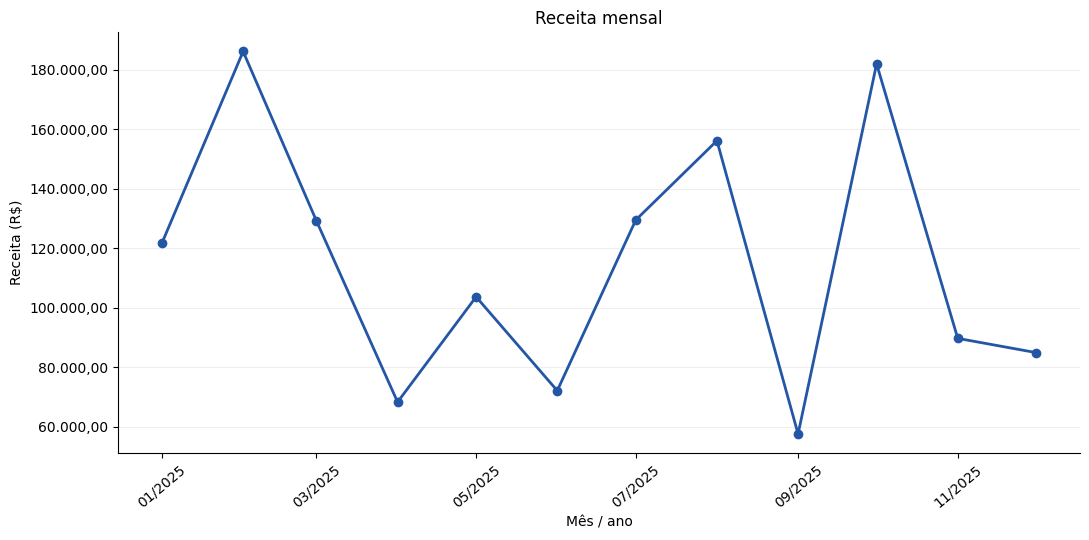

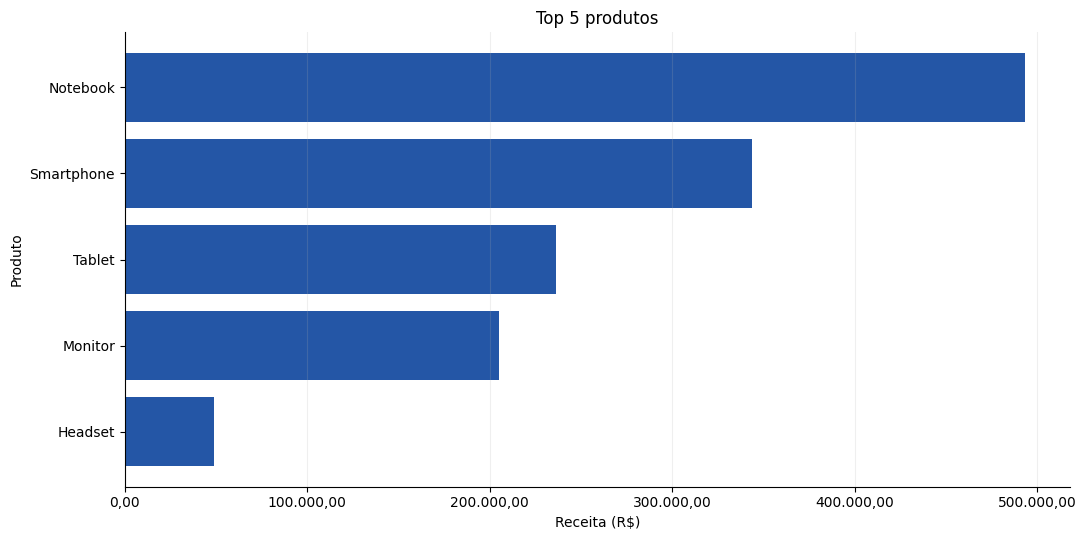

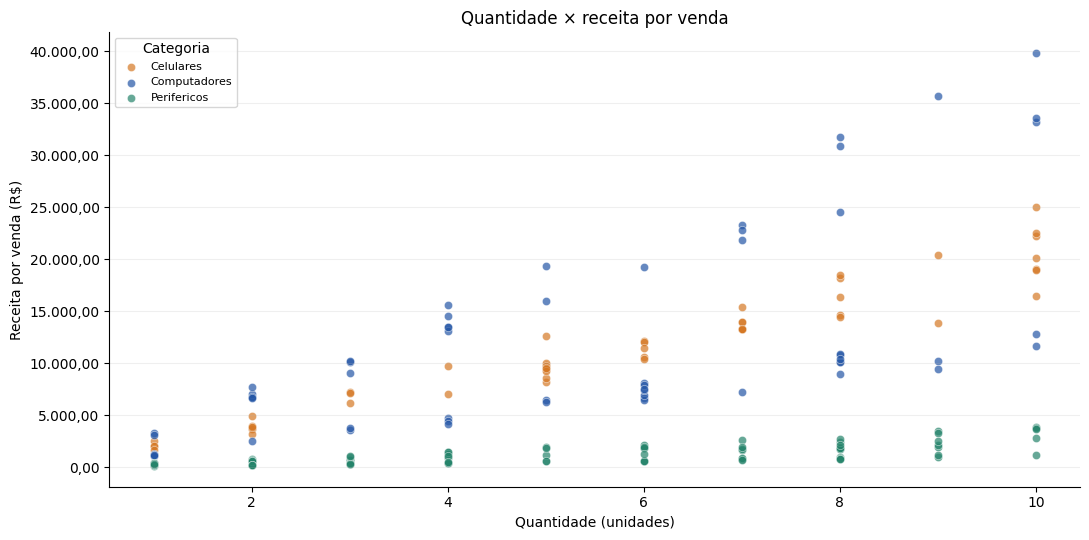

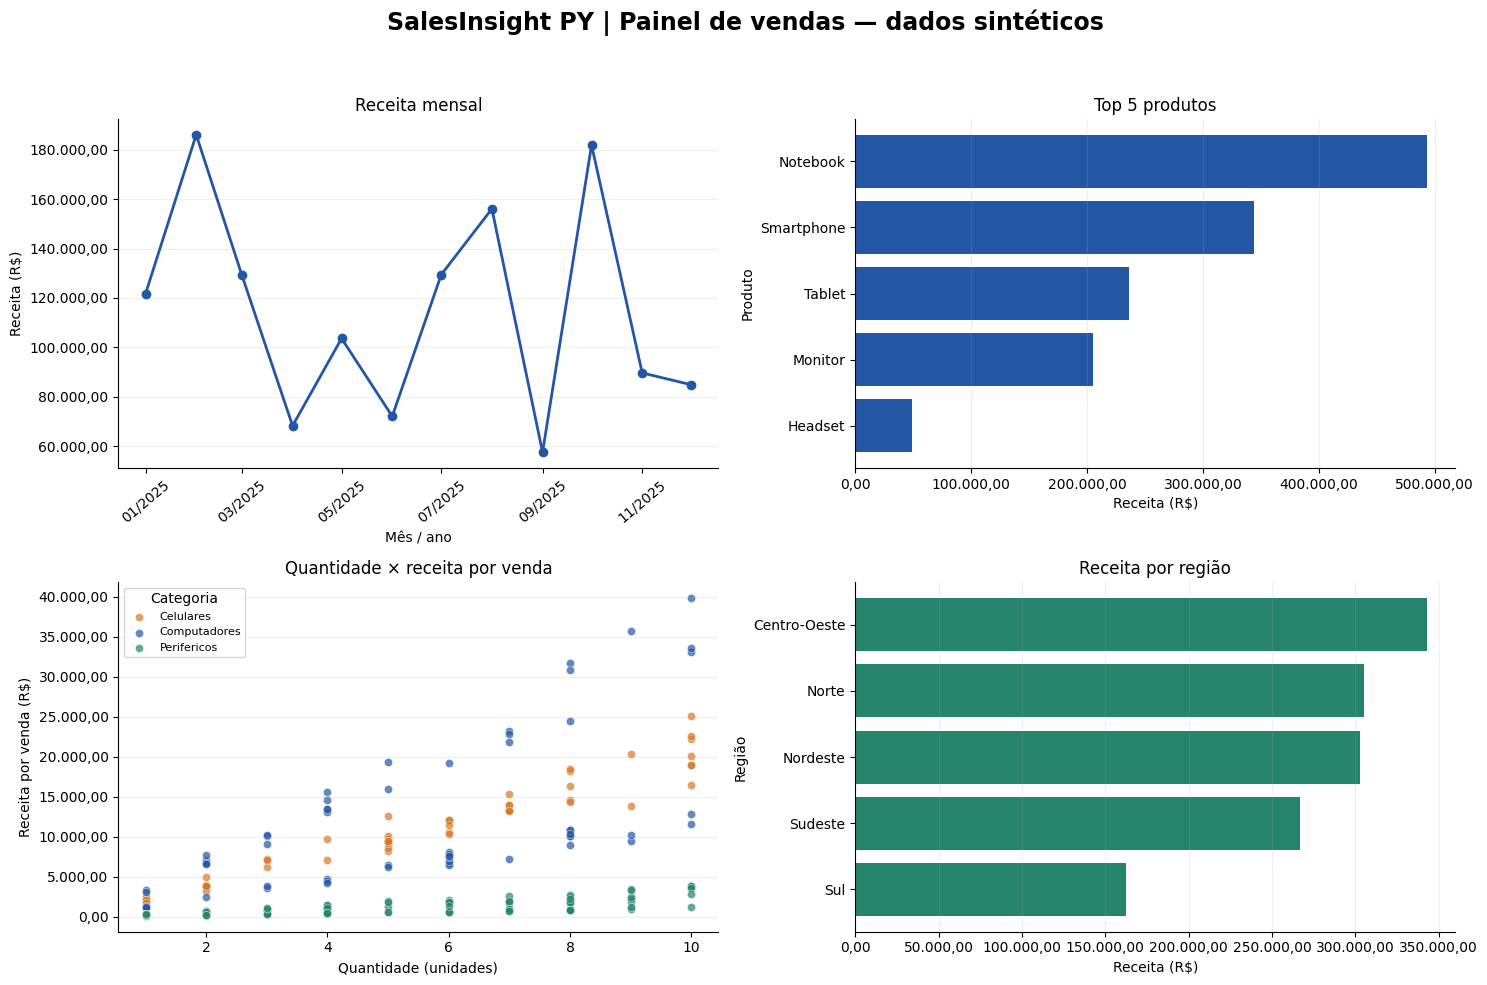

In [6]:
arquivos = criar_visualizacoes(df, metricas, mostrar=True)  # Mostra e salva figuras.

## Classe, exportações e main — RF08 a RF10

self identifica o analisador atual. Seus métodos coordenam as funções já estudadas. CSV armazena tabelas; JSON armazena indicadores. main ordena o fluxo. __name__ evita iniciar automaticamente quando o script é importado. A classe está prevista no enunciado.

In [7]:
# RF09–RF10: exportações e coordenação do fluxo.
def calcular_estatisticas(df):
    """Retorna indicadores simples usando tipos nativos serializáveis."""
    return {  # Dicionário: cada chave identifica um indicador.
        'receita_total': round(float(df['receita_total'].sum()), 2),  # Soma das receitas válidas.
        'quantidade_total': int(df['quantidade'].sum()),  # Total de unidades vendidas.
        'numero_vendas': int(len(df)),  # Uma linha representa uma venda.
        'numero_clientes': int(df['cliente'].nunique()),  # Conta clientes distintos.
        'ticket_medio': round(float(df['receita_total'].mean()), 2)  # Receita média por venda.
    }


def exportar_resultados(metricas, clientes, estatisticas, relatorio, pasta='outputs'):
    """Escreve CSV/JSON e relê o JSON para conferir a gravação."""
    destino = Path(pasta)  # Representa a pasta de saída.
    destino.mkdir(parents=True, exist_ok=True)  # Cria a pasta se necessário.
    metricas['por_mes'].to_csv(destino / 'metricas_por_mes.csv', index=False, encoding='utf-8-sig')  # Sem índice artificial.
    clientes.to_csv(destino / 'segmentacao_clientes.csv', index=False, encoding='utf-8-sig')  # Preserva os acentos.
    for nome in ['por_categoria', 'por_regiao', 'por_trimestre', 'top_produtos']:  # Guarda as tabelas auxiliares.
        metricas[nome].to_csv(destino / f'{nome}.csv', index=False, encoding='utf-8-sig')  # Exporta cada tabela.
    with open(destino / 'estatisticas_gerais.json', 'w', encoding='utf-8') as arquivo:  # Abre em modo de escrita.
        json.dump(estatisticas, arquivo, indent=4, ensure_ascii=False)  # Grava JSON legível.
    with open(destino / 'estatisticas_gerais.json', 'r', encoding='utf-8') as arquivo:  # Reabre em modo de leitura.
        conferencia = json.load(arquivo)  # Recupera os dados efetivamente salvos.
    assert conferencia == estatisticas, 'JSON diferente dos indicadores calculados.'  # Confere integridade.
    with open(destino / 'relatorio_limpeza.json', 'w', encoding='utf-8') as arquivo:  # Guarda a auditoria.
        json.dump(relatorio, arquivo, indent=4, ensure_ascii=False)  # Grava contagens da limpeza.
    print('JSON gravado e lido:', conferencia)  # Mostra a conferência exigida.
    return conferencia  # Permite reutilizar o resultado.


class AnalisadorDeVendas:  # A classe reúne dados e operações do mesmo analisador.
    """Coordena funções simples; self identifica esta instância do analisador."""
    def __init__(self, pasta_saida='outputs'):  # Inicializa um novo analisador.
        self.pasta_saida = Path(pasta_saida)  # Guarda onde salvar os resultados.

    def carregar(self, caminho):  # Recebe o caminho do CSV bruto.
        """Lê vendas e mantém a versão bruta para auditoria."""
        self.df_bruto = pd.read_csv(caminho)  # Lê a tabela do disco.
        return self.df_bruto  # Devolve a tabela carregada.

    def transformar(self):  # Executa limpeza antes das novas colunas.
        """Limpa os registros e cria as colunas derivadas."""
        limpo, self.relatorio = tratar_dados(self.df_bruto)  # Recebe os dois retornos da limpeza.
        self.df = criar_colunas(limpo)  # Calcula receita, calendário e faixas.
        return self.df  # Devolve a tabela pronta para análise.

    def analisar(self):  # Coordena as métricas e os segmentos.
        """Calcula tabelas agregadas, clientes e estatísticas gerais."""
        self.metricas = calcular_metricas(self.df)  # Agrupa as vendas em dimensões.
        self.clientes = segmentar_clientes(self.df)  # Classifica o gasto acumulado.
        self.estatisticas = calcular_estatisticas(self.df)  # Resume os indicadores.
        return self.metricas  # Devolve as tabelas agregadas.

    def visualizar(self, mostrar=False):  # Permite mostrar os gráficos no notebook.
        """Exporta as quatro figuras do projeto."""
        return criar_visualizacoes(self.df, self.metricas, self.pasta_saida / 'graficos', mostrar)  # Reutiliza o desenho.

    def resumo(self):  # Finaliza com arquivos e indicadores.
        """Exporta resultados e imprime o resumo executivo."""
        exportar_resultados(self.metricas, self.clientes, self.estatisticas, self.relatorio, self.pasta_saida)  # Salva e confere.
        print('Receita total: R$', moeda_br(self.estatisticas['receita_total']))  # Formata para leitura.
        print('Vendas válidas:', self.estatisticas['numero_vendas'])  # Mostra o volume de registros.
        return self.estatisticas  # Devolve o resumo.


def main(mostrar=False):  # Ponto de entrada do programa.
    """Executa todas as etapas em ordem e retorna o analisador."""
    caminho = Path('vendas.csv')  # Usa arquivo na pasta atual de execução.
    if not caminho.exists():  # Preserva um dataset já existente.
        gerar_dataset_vendas().to_csv(caminho, index=False)  # Gera a base somente quando faltar.
    analisador = AnalisadorDeVendas()  # Cria um objeto que coordena a análise.
    analisador.carregar(caminho)  # Lê o CSV bruto.
    inspecionar_dados(analisador.df_bruto)  # Mostra a estrutura inicial.
    analisador.transformar()  # Limpa e cria novas colunas.
    analisador.analisar()  # Calcula métricas e segmenta clientes.
    analisador.visualizar(mostrar)  # Salva os gráficos.
    analisador.resumo()  # Exporta os relatórios.
    print('[CONCLUÍDO] Fluxo executado sem erros.')  # Confirma a execução completa.
    return analisador  # Permite validar os resultados depois.


if __name__ == '__main__':  # Executa automaticamente apenas quando este arquivo é o programa principal.
    main()  # Inicia o fluxo completo.



Shape: (200, 8)
Colunas: ['id_venda', 'data_venda', 'cliente', 'produto', 'categoria', 'regiao', 'quantidade', 'preco_unitario']
Tipos:
 id_venda            int64
data_venda         object
cliente            object
produto            object
categoria          object
regiao             object
quantidade          int64
preco_unitario    float64
dtype: object
Nulos:
 id_venda          0
data_venda        0
cliente           0
produto           0
categoria         0
regiao            0
quantidade        0
preco_unitario    0
dtype: int64
Primeiras linhas:
  id_venda    data_venda     cliente    produto    categoria   regiao  quantidade  preco_unitario
        1    2025-05-21 Cliente_016      Mouse  Perifericos  Sudeste           2          102.90
        2 DATA INVALIDA Cliente_003      Mouse  Perifericos      Sul           9          105.13
        3    2025-10-15 Cliente_013 Smartphone    Celulares    Norte           9         2267.33
        4    2025-05-23 Cliente_001    Monitor Comput

JSON gravado e lido: {'receita_total': 1380210.31, 'quantidade_total': 1035, 'numero_vendas': 194, 'numero_clientes': 49, 'ticket_medio': 7114.49}
Receita total: R$ 1.380.210,31
Vendas válidas: 194
[CONCLUÍDO] Fluxo executado sem erros.


## Conclusões e limites

Receita de R$ 1.380.210,31; 194 vendas; 1.035 unidades; 49 clientes. Notebook lidera os produtos (R$ 493.242,63). Fevereiro lidera receita (R$ 186.065,22); outubro lidera número de vendas (25). Centro-Oeste lidera receita regional; Nordeste tem maior ticket médio. Segmentos: 35 Ouro, 9 Prata, 5 Bronze.

Dados sintéticos de 2025: não representam uma empresa real nem sustentam previsões. As seis datas inválidas foram excluídas de todas as métricas para manter a consistência. Em produção, recuperar datas na fonte seria preferível.